# Retail Demand Forecasting & Inventory Planning
**Walmart store CA_3 · Foods department · 1,437 products · May 2014 – May 2016**

**The business problem.** A store's food department has to decide every week how much of each product
to order. Order too little and shelves go empty (lost sales, unhappy customers); order too much and cash
sits in the backroom or spoils. This notebook answers four questions a department manager would ask:

1. **What does demand look like?** Trends, weekly rhythm, and what drives spikes.
2. **Which products matter most?** ABC (value) and XYZ (predictability) classification.
3. **How much will we sell over the next 4 weeks?** Forecasts tested against real held-out data.
4. **When should we reorder, and how much buffer do we need?** Safety stock and order-up-to levels per item.

Plus one question the data answered on its own: **how many sales are we losing to empty shelves?**

**Data:** [M5 Forecasting – Accuracy](https://www.kaggle.com/competitions/m5-forecasting-accuracy/data)
(real Walmart unit sales, prices and calendar). `src/prepare_data.py` filters it to store CA_3, Foods,
last 104 weeks.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CHARTS, OUTPUTS = ROOT / "charts", ROOT / "outputs"
CHARTS.mkdir(exist_ok=True); OUTPUTS.mkdir(exist_ok=True)

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#b8b6ae"
INK, INK2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#d6d5cf",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#ecebe7", "axes.axisbelow": True, "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(CHARTS / name, dpi=160)

df = pd.read_csv(ROOT / "data/processed/ca3_foods_daily.csv.gz", parse_dates=["date"])
df["revenue"] = df["units"] * df["sell_price"]
print(f"{len(df):,} rows · {df['item_id'].nunique():,} items · {df['date'].min():%d %b %Y} – {df['date'].max():%d %b %Y}")
df.head()

1,046,136 rows · 1,437 items · 26 May 2014 – 22 May 2016


,item_id,dept_id,units,date,wm_yr_wk,event_name_1,event_type_1,snap_CA,sell_price,revenue
0,FOODS_1_001,FOODS_1,0,2014-05-26,11417,MemorialDay,National,0,2.24,0.00
1,FOODS_1_001,FOODS_1,0,2014-05-27,11417,NaN,NaN,0,2.24,0.00
2,FOODS_1_001,FOODS_1,0,2014-05-28,11417,NaN,NaN,0,2.24,0.00
3,FOODS_1_001,FOODS_1,0,2014-05-29,11417,NaN,NaN,0,2.24,0.00
4,FOODS_1_001,FOODS_1,0,2014-05-30,11417,NaN,NaN,0,2.24,0.00


## 1. Data quality
Check before trusting anything: duplicates, impossible values, missing prices, and gaps in the calendar.

In [2]:
no_price = df["sell_price"].isna()
christmas = df["date"].dt.strftime("%m-%d").eq("12-25")
item_totals = df.groupby("item_id")["units"].sum()

dq = pd.DataFrame([
    ("Duplicate item-day rows", df.duplicated(["item_id", "date"]).sum()),
    ("Negative unit sales", (df["units"] < 0).sum()),
    ("Missing calendar days", 728 - df["date"].nunique()),
    ("Item-days with no price (not on sale yet)", no_price.sum()),
    ("…of which recorded a sale", (no_price & (df["units"] > 0)).sum()),
    ("Items with zero sales in 2 years", (item_totals == 0).sum()),
    ("Units sold on Christmas Day (all items)", df.loc[christmas, "units"].sum()),
], columns=["check", "result"])
dq

,check,result
0,Duplicate item-day rows,0
1,Negative unit sales,0
2,Missing calendar days,0
3,Item-days with no price (not on sale yet),16327
4,…of which recorded a sale,0
5,Items with zero sales in 2 years,0
6,Units sold on Christmas Day (all items),4


**What this means and how it's handled**
- No duplicates, negatives or missing days — the data is structurally clean.
- **Missing prices = the product wasn't on the shelf yet** (new launches). No sales were recorded on those days,
  so they are excluded from stockout detection and demand statistics rather than treated as zero demand.
- **Christmas Day has ~0 sales because the store is closed.** It is excluded from daily statistics and, for the
  daily forecast, filled from neighbouring days so the model doesn't learn a fake demand crash.
- Items with no sales at all are dropped from forecasting.

In [3]:
listed = df[~no_price & ~christmas].copy()        # days the item was actually for sale and the store was open
active_items = item_totals[item_totals > 0].index
listed = listed[listed["item_id"].isin(active_items)]
print(f"Analysis base: {len(listed):,} item-days for {listed['item_id'].nunique():,} items")

Analysis base: 1,026,971 item-days for 1,437 items


## 2. What does demand look like?

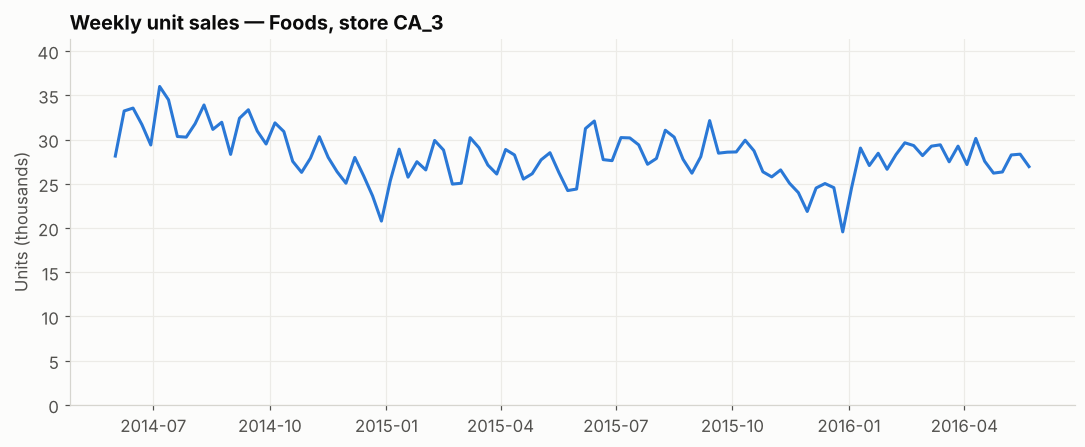

Weekly average: 28,193 units / $73,060
Last 52 weeks vs previous 52 weeks: -3.7% units


In [4]:
daily = df.groupby("date").agg(units=("units", "sum"), revenue=("revenue", "sum"),
                               snap=("snap_CA", "first"), event=("event_name_1", "first"))
weekly = daily.resample("W-SUN").agg({"units": "sum", "revenue": "sum"})

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(weekly.index, weekly["units"] / 1e3, color=BLUE, lw=2)
ax.set_title("Weekly unit sales — Foods, store CA_3")
ax.set_ylabel("Units (thousands)")
ax.set_ylim(0, weekly["units"].max() / 1e3 * 1.15)
save(fig, "01_weekly_sales.png"); plt.show()

yoy = weekly["units"].iloc[-52:].sum() / weekly["units"].iloc[:52].sum() - 1
print(f"Weekly average: {weekly['units'].mean():,.0f} units / ${weekly['revenue'].mean():,.0f}")
print(f"Last 52 weeks vs previous 52 weeks: {yoy:+.1%} units")

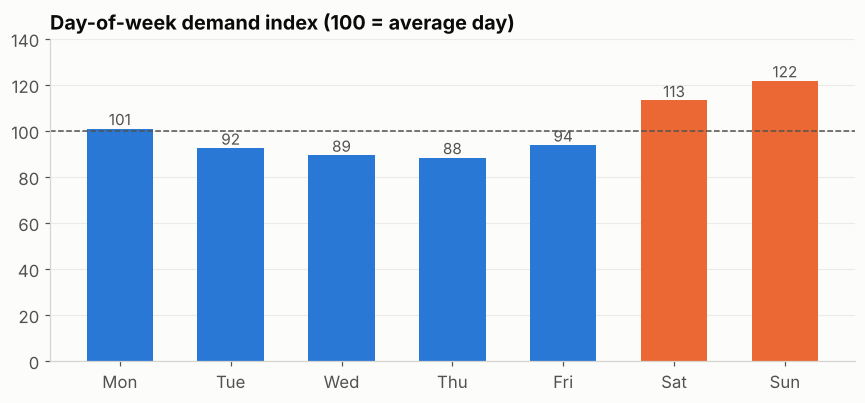

date
Monday      101.00
Tuesday      92.50
Wednesday    89.40
Thursday     88.40
Friday       93.80
Saturday    113.20
Sunday      121.70
Name: units, dtype: float64

In [5]:
open_days = daily[~daily.index.strftime("%m-%d").isin(["12-25"])]
dow = open_days.groupby(open_days.index.day_name())["units"].mean()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow_index = (dow / dow.mean() * 100).reindex(order)

fig, ax = plt.subplots(figsize=(8, 3.8))
cols = [ORANGE if d in ("Saturday", "Sunday") else BLUE for d in order]
ax.bar([d[:3] for d in order], dow_index, color=cols, width=0.6)
ax.axhline(100, color=INK2, lw=1, ls="--")
for x, v in enumerate(dow_index):
    ax.text(x, v + 1.5, f"{v:.0f}", ha="center", color=INK2, fontsize=10)
ax.set_title("Day-of-week demand index (100 = average day)")
ax.set_ylim(0, dow_index.max() * 1.15)
ax.grid(axis="x", visible=False)
save(fig, "02_day_of_week.png"); plt.show()
dow_index.round(1)

### Do SNAP benefit days lift food sales?
In California, SNAP (food-stamp) benefits are issued on set days each month (`snap_CA = 1`).
Weekdays matter too, so compare SNAP vs non-SNAP **within each weekday**, then test the overall difference.

In [6]:
od = open_days.assign(weekday=open_days.index.day_name())
by_wd = od.groupby(["weekday", "snap"])["units"].mean().unstack()
by_wd["lift_%"] = (by_wd[1] / by_wd[0] - 1) * 100
by_wd = by_wd.reindex(order)

snap_days, other_days = od.loc[od["snap"] == 1, "units"], od.loc[od["snap"] == 0, "units"]
t, p = stats.ttest_ind(snap_days, other_days, equal_var=False)     # Welch's t-test
lift = snap_days.mean() / other_days.mean() - 1
print(f"SNAP days: {snap_days.mean():,.0f} units/day vs {other_days.mean():,.0f} on other days  ->  {lift:+.1%}")
print(f"Welch t-test: t = {t:.2f}, p = {p:.2g}")
print(f"Lift is positive on {(by_wd['lift_%'] > 0).sum()} of 7 weekdays")
by_wd.round(1)

SNAP days: 4,328 units/day vs 3,896 on other days  ->  +11.1%
Welch t-test: t = 8.23, p = 1.9e-15
Lift is positive on 7 of 7 weekdays


snap,0,1,lift_%
weekday,,,
Monday,"3,925.00","4,378.40",11.60
Tuesday,"3,568.20","4,032.80",13.00
Wednesday,"3,448.30","3,929.00",13.90
Thursday,"3,412.40","3,899.80",14.30
Friday,"3,663.30","4,053.70",10.70
Saturday,"4,431.60","4,881.80",10.20
Sunday,"4,798.60","5,146.00",7.20


SNAP days carry a clear, statistically significant lift on every weekday — so ordering should be
**front-loaded ahead of the SNAP window**, not spread evenly across the month.

## 3. Which products matter most? ABC–XYZ classification
- **ABC (value):** A = items making up the top 80% of revenue over the last 52 weeks, B = next 15%, C = last 5%.
- **XYZ (predictability):** coefficient of variation of weekly units. X < 0.5 (steady), Y 0.5–1.0, Z > 1.0 (erratic).

In [7]:
last52 = df[df["date"] > df["date"].max() - pd.Timedelta(weeks=52)]
item_week = (last52.groupby(["item_id", pd.Grouper(key="date", freq="W-SUN")])["units"].sum().unstack(fill_value=0))
rev52 = last52.groupby("item_id")["revenue"].sum()
rev52 = rev52[rev52 > 0].sort_values(ascending=False)

abc = pd.DataFrame({"revenue_52w": rev52})
abc["cum_share"] = abc["revenue_52w"].cumsum() / abc["revenue_52w"].sum()
abc["abc"] = np.select([abc["cum_share"] <= 0.80, abc["cum_share"] <= 0.95], ["A", "B"], "C")
wk = item_week.loc[abc.index]
abc["avg_weekly_units"] = wk.mean(axis=1)
abc["cv"] = wk.std(axis=1) / wk.mean(axis=1)
abc["xyz"] = pd.cut(abc["cv"], [-np.inf, 0.5, 1.0, np.inf], labels=["X", "Y", "Z"]).astype(str)
abc["dept_id"] = abc.index.str.rsplit("_", n=1).str[0]

summary = abc.groupby("abc").agg(items=("revenue_52w", "size"), revenue=("revenue_52w", "sum"))
summary["% items"] = summary["items"] / summary["items"].sum() * 100
summary["% revenue"] = summary["revenue"] / summary["revenue"].sum() * 100
display(summary.round(1))
pd.crosstab(abc["abc"], abc["xyz"], margins=True)

,items,revenue,% items,% revenue
abc,,,,
A,584,"3,034,373.70",40.60,80.00
B,472,"569,046.40",32.80,15.00
C,381,"190,366.20",26.50,5.00


xyz,X,Y,Z,All
abc,,,,
A,337,218,29,584
B,148,283,41,472
C,27,239,115,381
All,512,740,185,1437


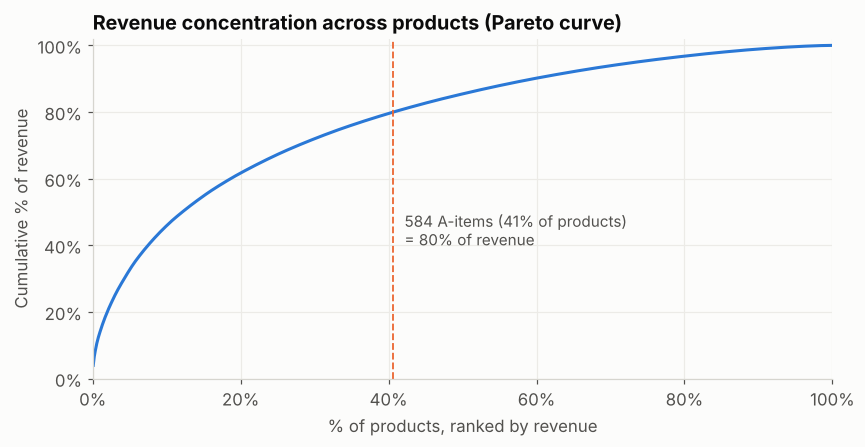

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(1, len(abc) + 1) / len(abc) * 100
ax.plot(x, abc["cum_share"] * 100, color=BLUE, lw=2)
n_a = (abc["abc"] == "A").sum()
ax.axvline(n_a / len(abc) * 100, color=ORANGE, lw=1.2, ls="--")
ax.text(n_a / len(abc) * 100 + 1.5, 40,
        f"{n_a} A-items ({n_a/len(abc):.0%} of products)\n= 80% of revenue", color=INK2, fontsize=10)
ax.set_title("Revenue concentration across products (Pareto curve)")
ax.set_xlabel("% of products, ranked by revenue"); ax.set_ylabel("Cumulative % of revenue")
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, 102); ax.set_xlim(0, 100)
save(fig, "03_abc_pareto.png"); plt.show()

## 4. Forecasting the next 4 weeks

### 4a. Department level (daily, 28-day horizon)
Hold out the **last 28 days** (25 Apr – 22 May 2016), train on everything before, and compare
three methods against what actually sold:
- **Seasonal naive** — each day = same weekday last week (the "do nothing smart" benchmark)
- **Weekday average** — mean of the last 4 same weekdays
- **Holt-Winters** — exponential smoothing with trend and weekly seasonality

In [9]:
def wape(actual, forecast):
    return np.abs(actual - forecast).sum() / np.abs(actual).sum() * 100

def bias(actual, forecast):
    return (forecast.sum() - actual.sum()) / actual.sum() * 100

def mape(actual, forecast):
    return (np.abs(actual - forecast) / actual).mean() * 100

series = daily["units"].astype(float).copy()
xmas = series.index.strftime("%m-%d") == "12-25"
series[xmas] = np.nan
series = series.interpolate()                    # store closed -> fill from neighbouring days

H = 28
train, test = series.iloc[:-H], series.iloc[-H:]

f_snaive = pd.Series(np.tile(train.iloc[-7:].values, 4), index=test.index)
f_wdavg = pd.Series(np.tile(train.iloc[-28:].values.reshape(4, 7).mean(axis=0), 4), index=test.index)
hw = ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="mul", seasonal_periods=7).fit()
f_hw = pd.Series(hw.forecast(H).values, index=test.index)

dept_results = pd.DataFrame({
    name: {"MAPE %": mape(test, f), "WAPE %": wape(test, f), "Bias %": bias(test, f),
           "4-week total error %": abs(bias(test, f))}
    for name, f in [("Seasonal naive", f_snaive), ("Weekday average", f_wdavg), ("Holt-Winters", f_hw)]
}).T
dept_results.round(1)

,MAPE %,WAPE %,Bias %,4-week total error %
Seasonal naive,6.80,6.90,-4.60,4.60
Weekday average,6.30,6.30,1.10,1.10
Holt-Winters,6.00,6.00,-3.10,3.10


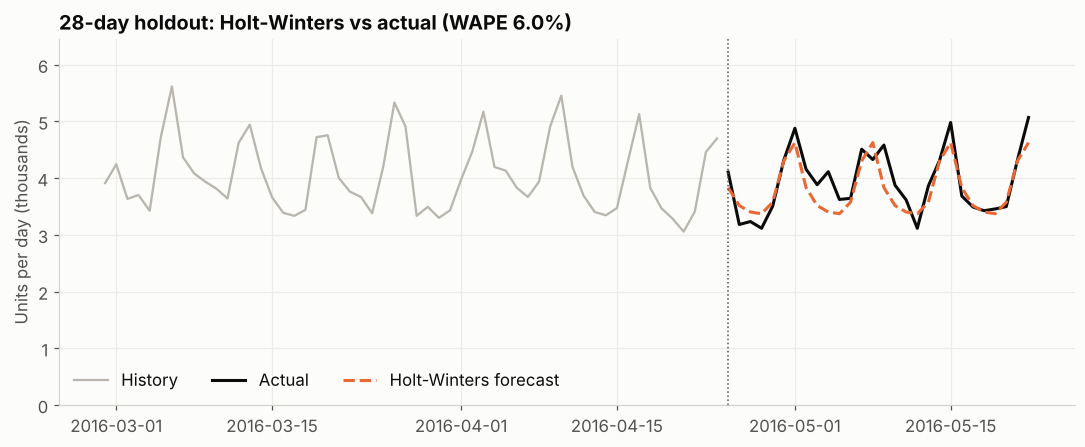

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.2))
hist = series.iloc[-H - 56:-H]
ax.plot(hist.index, hist / 1e3, color=GRAY, lw=1.5, label="History")
ax.plot(test.index, test / 1e3, color=INK, lw=2, label="Actual")
ax.plot(test.index, f_hw / 1e3, color=ORANGE, lw=2, ls="--", label="Holt-Winters forecast")
ax.axvline(test.index[0], color=INK2, lw=1, ls=":")
ax.set_title(f"28-day holdout: Holt-Winters vs actual (WAPE {dept_results.loc['Holt-Winters', 'WAPE %']:.1f}%)")
ax.set_ylabel("Units per day (thousands)")
ax.set_ylim(0, series.iloc[-H - 56:].max() / 1e3 * 1.15)
ax.legend(frameon=False, loc="lower left", ncols=3)
save(fig, "04_forecast_holdout.png"); plt.show()

### 4b. Item level (weekly, 4-week horizon)
Ordering happens per product, so test forecasting methods on **every item**: train on weeks 1–100,
forecast weeks 101–104, and score the A-items (where errors cost the most) and all items.

In [11]:
weekly_item = (df[df["item_id"].isin(abc.index)]
               .groupby(["item_id", pd.Grouper(key="date", freq="W-SUN")])["units"].sum()
               .unstack(fill_value=0))
tr, te = weekly_item.iloc[:, :-4], weekly_item.iloc[:, -4:]

def ses_forecast(row, h=4):
    y = row.values.astype(float)
    y = y[np.argmax(y > 0):] if (y > 0).any() else y       # start at first sale (new launches)
    if len(y) < 8 or y.sum() == 0:
        return np.repeat(y[-4:].mean() if len(y) else 0.0, h)
    fit = SimpleExpSmoothing(y, initialization_method="estimated").fit()
    return np.repeat(fit.forecast(1)[0], h)

methods = {
    "Naive (last week)": np.repeat(tr.iloc[:, -1:].values, 4, axis=1),
    "4-week moving avg": np.repeat(tr.iloc[:, -4:].mean(axis=1).values[:, None], 4, axis=1),
    "8-week moving avg": np.repeat(tr.iloc[:, -8:].mean(axis=1).values[:, None], 4, axis=1),
    "Exponential smoothing": np.vstack([ses_forecast(r) for _, r in tr.iterrows()]),
}
is_a = weekly_item.index.isin(abc.index[abc["abc"] == "A"])
item_results = pd.DataFrame({
    m: {"WAPE % (A items)": wape(te.values[is_a], f[is_a]),
        "WAPE % (all items)": wape(te.values, f),
        "Bias % (all items)": bias(te.values, f)}
    for m, f in methods.items()
}).T
item_results.round(1)

,WAPE % (A items),WAPE % (all items),Bias % (all items)
Naive (last week),29.40,35.50,-4.60
4-week moving avg,30.30,34.90,1.10
8-week moving avg,33.40,37.10,3.00
Exponential smoothing,28.30,33.30,-0.20


In [12]:
best = item_results["WAPE % (A items)"].idxmin()
print(f"Best item-level method: {best}")
imp = 1 - item_results.loc[best, "WAPE % (A items)"] / item_results.loc["Naive (last week)", "WAPE % (A items)"]
print(f"Error reduction vs naive on A-items: {imp:.0%}")

Best item-level method: Exponential smoothing
Error reduction vs naive on A-items: 4%


Item-level weekly demand is much noisier than the department total, so errors are higher — that's normal,
and exactly why safety stock exists. Exponential smoothing wins, but only modestly: at the item level, most of the
error is noise no method can predict. That is the honest takeaway — better forecasts help a little, while the
buffer (safety stock) and catching empty shelves fast help a lot.

## 5. Inventory policy: safety stock and order-up-to levels

**Assumptions** (state them — a manager will ask):
- Orders are placed **weekly** (review period R = 1 week) and arrive **1 week** later (lead time L = 1 week).
- Target service level (chance of not running out between deliveries): **A = 98%, B = 95%, C = 90%**.
- Demand uncertainty σ = standard deviation of **forecast errors** over the last 26 weeks (how wrong a
  simple 4-week-average forecast was each week). This is safer than the plain spread of demand, because what
  safety stock really protects against is the forecast being wrong.

**Formulas** (periodic review):
- Safety stock = z × σ × √(L + R)
- Order-up-to level S = forecast weekly demand × (L + R) + safety stock
- Each week: order quantity = S − (stock on hand + stock on order)

In [13]:
L, R = 1, 1

def error_sigma(weekly_units, window=26):
    """Std of one-week-ahead errors of a 4-week moving-average forecast, over the last `window` weeks."""
    fc = weekly_units.T.rolling(4).mean().shift(1).T
    err = (weekly_units - fc).iloc[:, -window:]
    return err.std(axis=1)

z_by_class = {"A": stats.norm.ppf(0.98), "B": stats.norm.ppf(0.95), "C": stats.norm.ppf(0.90)}
final_forecast = pd.Series(np.vstack([ses_forecast(r) for _, r in weekly_item.iterrows()])[:, 0],
                           index=weekly_item.index)        # retrained on all 104 weeks
last_price = df.sort_values("date").groupby("item_id")["sell_price"].last()

plan = abc[["dept_id", "abc", "xyz", "avg_weekly_units", "cv"]].copy()
plan["forecast_weekly_units"] = final_forecast
plan["forecast_next_4_weeks"] = final_forecast * 4
plan["sigma_weekly"] = error_sigma(weekly_item)
plan["service_level"] = plan["abc"].map({"A": 0.98, "B": 0.95, "C": 0.90})
plan["safety_stock_units"] = np.ceil(plan["abc"].map(z_by_class) * plan["sigma_weekly"] * np.sqrt(L + R))
plan["order_up_to_level"] = np.ceil(plan["forecast_weekly_units"] * (L + R) + plan["safety_stock_units"])
plan["unit_price"] = last_price
plan["safety_stock_value"] = plan["safety_stock_units"] * plan["unit_price"]
plan = plan.round(2)
plan.to_csv(OUTPUTS / "reorder_plan.csv")

ss = plan.groupby("abc").agg(items=("abc", "size"), safety_stock_units=("safety_stock_units", "sum"),
                             safety_stock_value=("safety_stock_value", "sum"))
ss["% of SS value"] = ss["safety_stock_value"] / ss["safety_stock_value"].sum() * 100
display(ss.round(1))
plan.sort_values("forecast_weekly_units", ascending=False).head(10)

,items,safety_stock_units,safety_stock_value,% of SS value
abc,,,,
A,584,"23,372.00","70,419.40",76.10
B,472,"7,109.00","16,137.80",17.50
C,381,"2,647.00","5,921.00",6.40


,dept_id,abc,xyz,avg_weekly_units,cv,forecast_weekly_units,forecast_next_4_weeks,sigma_weekly,service_level,safety_stock_units,order_up_to_level,unit_price,safety_stock_value
item_id,,,,,,,,,,,,,
FOODS_3_090,FOODS_3,A,X,692.12,0.43,705.53,"2,822.13",283.33,0.98,823.00,"2,235.00",1.60,"1,316.80"
FOODS_3_681,FOODS_3,A,Y,274.35,0.56,490.54,"1,962.15",90.72,0.98,264.00,"1,246.00",1.00,264.00
FOODS_3_586,FOODS_3,A,X,510.48,0.15,474.78,"1,899.11",58.50,0.98,170.00,"1,120.00",1.68,285.60
FOODS_3_252,FOODS_3,A,X,324.44,0.24,359.28,"1,437.14",49.72,0.98,145.00,864.00,1.58,229.10
FOODS_3_120,FOODS_3,A,X,579.88,0.35,352.68,"1,410.72",156.44,0.98,455.00,"1,161.00",4.98,"2,265.90"
FOODS_3_086,FOODS_3,A,Y,122.94,0.67,235.36,941.43,49.77,0.98,145.00,616.00,1.00,145.00
FOODS_3_555,FOODS_3,A,X,209.56,0.14,221.43,885.74,23.33,0.98,68.00,511.00,1.68,114.24
FOODS_3_288,FOODS_3,A,X,230.94,0.35,218.32,873.27,48.08,0.98,140.00,577.00,1.50,210.00
FOODS_3_587,FOODS_3,A,X,232.35,0.20,218.05,872.22,32.99,0.98,96.00,533.00,2.48,238.08


### Sanity check: would this policy have worked?
Back-test on the held-out weeks: set the order-up-to level from training data only, then check every
2-week window (L + R) in the test period — did actual demand stay within the stock the policy would have provided?

In [14]:
f_train = pd.Series(methods["Exponential smoothing"][:, 0], index=weekly_item.index)
sigma_train = error_sigma(tr)
z = abc["abc"].reindex(weekly_item.index).map(z_by_class)
cover = f_train * (L + R) + z * sigma_train * np.sqrt(L + R)      # order-up-to level from training data
two_week_demand = te.values[:, :-1] + te.values[:, 1:]             # 3 overlapping 2-week windows
covered = two_week_demand <= cover.values[:, None]
bt = pd.DataFrame({"abc": abc["abc"].reindex(weekly_item.index), "covered_%": covered.mean(axis=1) * 100})
check = bt.groupby("abc")["covered_%"].mean().round(1).to_frame("achieved in-stock rate %")
check["target %"] = [98, 95, 90]
check

,achieved in-stock rate %,target %
abc,,
A,94.90,98
B,90.20,95
C,79.70,90


**Honest read:** the policy lands **3–10 points under target**. The formula assumes forecast errors are normally
distributed, but weekly item demand is lumpy (promotions, SNAP weeks, small counts), so the tails are fatter than
the formula expects. Two fixes before using this for real: (1) calibrate z upward per class until a rolling
back-test hits target, or (2) set safety stock from empirical error quantiles instead of z × σ.
Catching this in a back-test — instead of in empty shelves — is the point of testing.

## 6. How many sales are we losing to empty shelves?
A product that normally sells **2+ units a day** and then records **7–28 days in a row of zero sales — while
it's still listed and the store is open — and then starts selling again** is almost certainly out of stock
(for a Poisson rate of 2/day, seven straight zero days has a probability below 1 in a million).
Lost units are estimated from the item's average daily sales over the 28 days before the gap.
Gaps longer than 28 days are left out: those look like seasonal or temporarily delisted products, not empty
shelves, and counting them would inflate the estimate.

In [15]:
events = []
for item, g in listed.sort_values("date").groupby("item_id"):
    u = g.set_index("date")["units"]
    rate = u.rolling(28, min_periods=21).mean().shift(1)   # demand before each day
    zero = u.eq(0)
    run_id = (zero != zero.shift()).cumsum()
    for _, run in u[zero].groupby(run_id[zero]):
        start, end = run.index[0], run.index[-1]
        before = rate.get(start, np.nan)
        resumed = end < u.index[-1]                       # exclude gaps at the very end (possible delisting)
        if 7 <= len(run) <= 28 and before >= 2 and resumed:
            price = g.loc[g["date"].between(start, end), "sell_price"].mean()
            events.append({"item_id": item, "start": start, "days": len(run),
                           "avg_daily_before": before, "lost_units": before * len(run),
                           "lost_revenue": before * len(run) * price})
oos = pd.DataFrame(events)
oos["abc"] = oos["item_id"].map(abc["abc"])
total_rev = df["revenue"].sum()
print(f"Likely stockout events: {len(oos):,} across {oos['item_id'].nunique():,} items")
print(f"Estimated lost revenue: ${oos['lost_revenue'].sum():,.0f} over 2 years "
      f"({oos['lost_revenue'].sum() / total_rev:.1%} of actual revenue)")
print(f"Median gap: {oos['days'].median():.0f} days; share of lost revenue on A-items: "
      f"{oos.loc[oos['abc'] == 'A', 'lost_revenue'].sum() / oos['lost_revenue'].sum():.0%}")
oos.to_csv(OUTPUTS / "stockout_events.csv", index=False)
oos.sort_values("lost_revenue", ascending=False).head(10)

Likely stockout events: 867 across 431 items
Estimated lost revenue: $115,159 over 2 years (1.5% of actual revenue)
Median gap: 9 days; share of lost revenue on A-items: 85%


,item_id,start,days,avg_daily_before,lost_units,lost_revenue,abc
99,FOODS_1_180,2015-03-02,17,21.54,366.11,"3,572.56",A
363,FOODS_3_120,2016-02-26,10,69.43,694.29,"3,318.69",A
100,FOODS_1_180,2015-12-21,17,8.39,142.68,"1,422.51",A
624,FOODS_3_469,2015-09-25,23,8.00,184.00,"1,148.16",A
523,FOODS_3_368,2014-06-17,21,8.64,181.36,"1,084.55",A
818,FOODS_3_785,2015-09-17,20,16.29,325.71,944.57,A
253,FOODS_2_318,2014-07-23,28,6.43,180.00,894.60,A
364,FOODS_3_124,2015-04-18,13,12.64,164.36,862.75,A
149,FOODS_2_029,2014-07-30,17,4.68,79.54,793.77,A
655,FOODS_3_541,2014-10-03,14,58.21,815.00,773.09,A


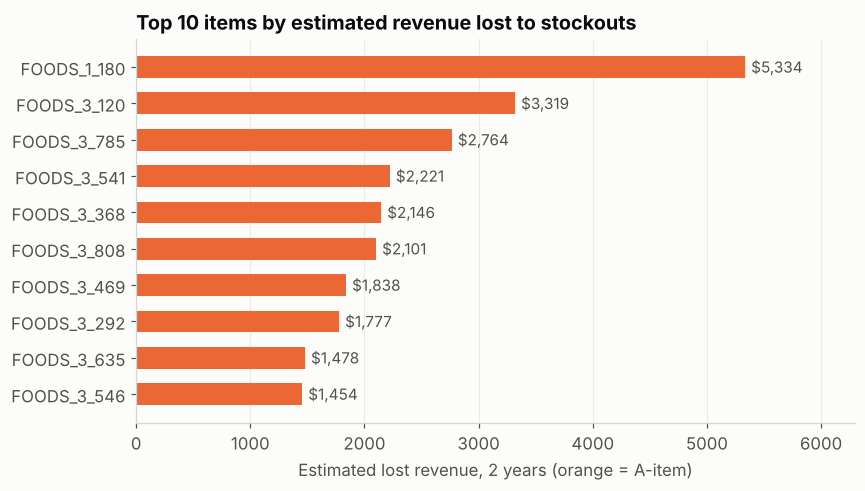

In [16]:
top = (oos.groupby("item_id")["lost_revenue"].sum().sort_values().tail(10))
fig, ax = plt.subplots(figsize=(8, 4.6))
cols = [ORANGE if abc["abc"].get(i) == "A" else BLUE for i in top.index]
ax.barh(top.index, top.values, color=cols, height=0.6)
for y, v in enumerate(top.values):
    ax.text(v + top.max() * 0.01, y, f"${v:,.0f}", va="center", fontsize=10, color=INK2)
ax.set_title("Top 10 items by estimated revenue lost to stockouts")
ax.set_xlabel("Estimated lost revenue, 2 years (orange = A-item)")
ax.set_xlim(0, top.max() * 1.18)
ax.grid(axis="y", visible=False)
save(fig, "05_stockout_losses.png"); plt.show()

## 7. Findings and recommendations
The numbers below are printed from the analysis above, so they always match the data.

In [17]:
a_share = summary.loc["A", "% items"]
print(f"""
1. DEMAND: ~{weekly['units'].mean():,.0f} units/week; last 52 weeks {yoy:+.1%} vs prior year.
   Weekends run {dow_index[['Saturday','Sunday']].mean() - 100:+.0f}% above an average day; SNAP days {lift:+.1%} (p = {p:.1g}).
2. FOCUS: {summary.loc['A','items']} A-items ({a_share:.0f}% of products) make 80% of revenue.
3. FORECAST: Holt-Winters department forecast WAPE {dept_results.loc['Holt-Winters','WAPE %']:.1f}%
   vs {dept_results.loc['Seasonal naive','WAPE %']:.1f}% for seasonal naive; 4-week total off by {dept_results.loc['Holt-Winters','4-week total error %']:.1f}%.
   Item level: {best} cut A-item error {imp:.0%} vs repeating last week.
4. INVENTORY: safety stock for all items ≈ {plan['safety_stock_units'].sum():,.0f} units (${plan['safety_stock_value'].sum():,.0f});
   A-items hold {ss.loc['A','% of SS value']:.0f}% of that value.
5. STOCKOUTS: {len(oos):,} likely out-of-stock gaps on {oos['item_id'].nunique()} items ≈ ${oos['lost_revenue'].sum():,.0f} lost revenue.
""")


1. DEMAND: ~28,193 units/week; last 52 weeks -3.7% vs prior year.
   Weekends run +17% above an average day; SNAP days +11.1% (p = 2e-15).
2. FOCUS: 584 A-items (41% of products) make 80% of revenue.
3. FORECAST: Holt-Winters department forecast WAPE 6.0%
   vs 6.9% for seasonal naive; 4-week total off by 3.1%.
   Item level: Exponential smoothing cut A-item error 4% vs repeating last week.
4. INVENTORY: safety stock for all items ≈ 33,128 units ($92,478);
   A-items hold 76% of that value.
5. STOCKOUTS: 867 likely out-of-stock gaps on 431 items ≈ $115,159 lost revenue.



**Recommendations**
1. **Run a daily zero-sales exception report** for A-items: any A-item with 2+ days of zero sales gets a shelf
   check. The typical gap above lasted over a week before sales resumed; catching it in 2 days recovers most of that.
2. **Order to the order-up-to levels in `outputs/reorder_plan.csv`** (smoothed forecast + safety stock), after
   calibrating the safety factor as noted in the back-test.
3. **Front-load orders before SNAP days and weekends** — the lift is consistent and predictable.
4. **Spend buffer where it pays:** higher service levels for A-items, leaner for C-items.

**Limitations:** no on-hand inventory data, so stockouts are inferred from sales patterns; lead time and service
levels are assumptions to be replaced with the store's real values; prices are shelf prices, not margins.